In [1]:
import os, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.analysis.data import *
from cifresignificative.viz.style import *
apply_style()
panel = load_panel()


# 02 - Italy vs the rest of the EU27: growth, productivity, convergence
Italy in blue, the median of the other 26 members in orange (dashed), all other EU27 countries in gray.

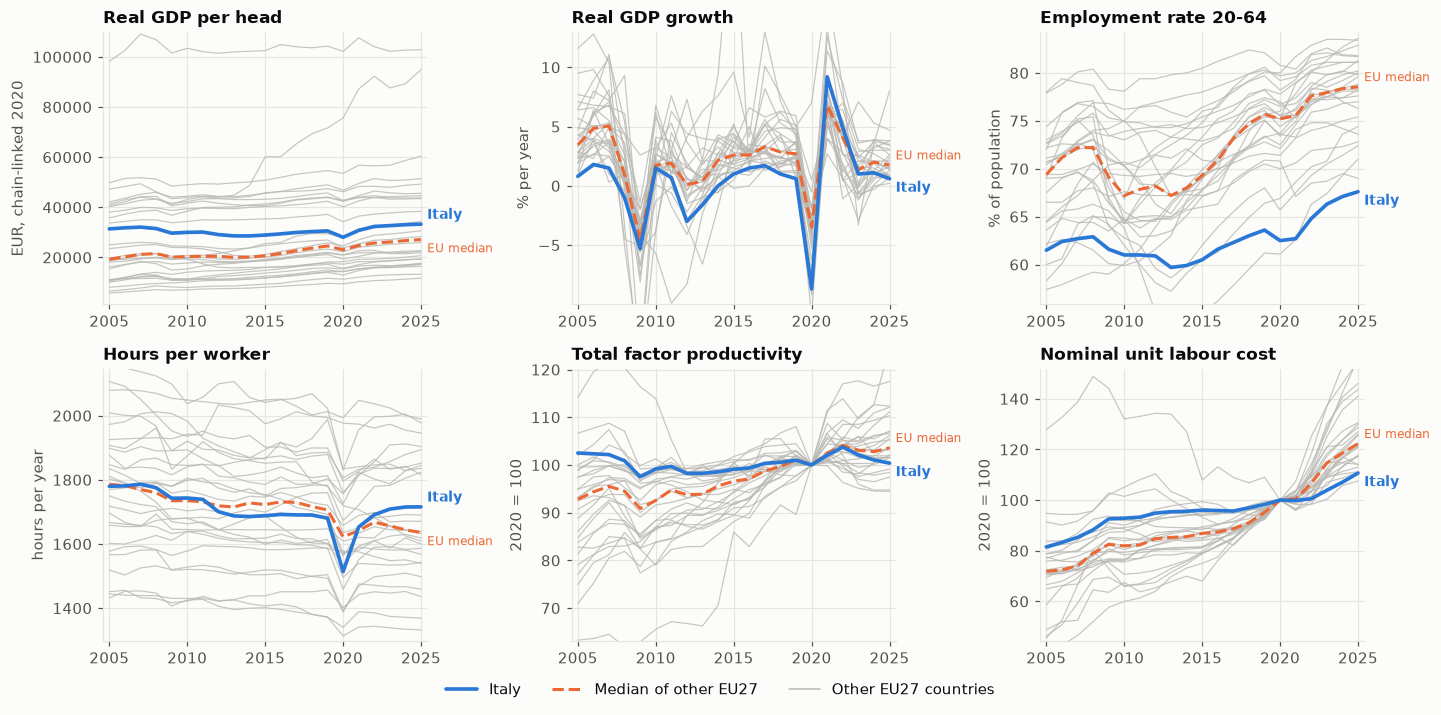

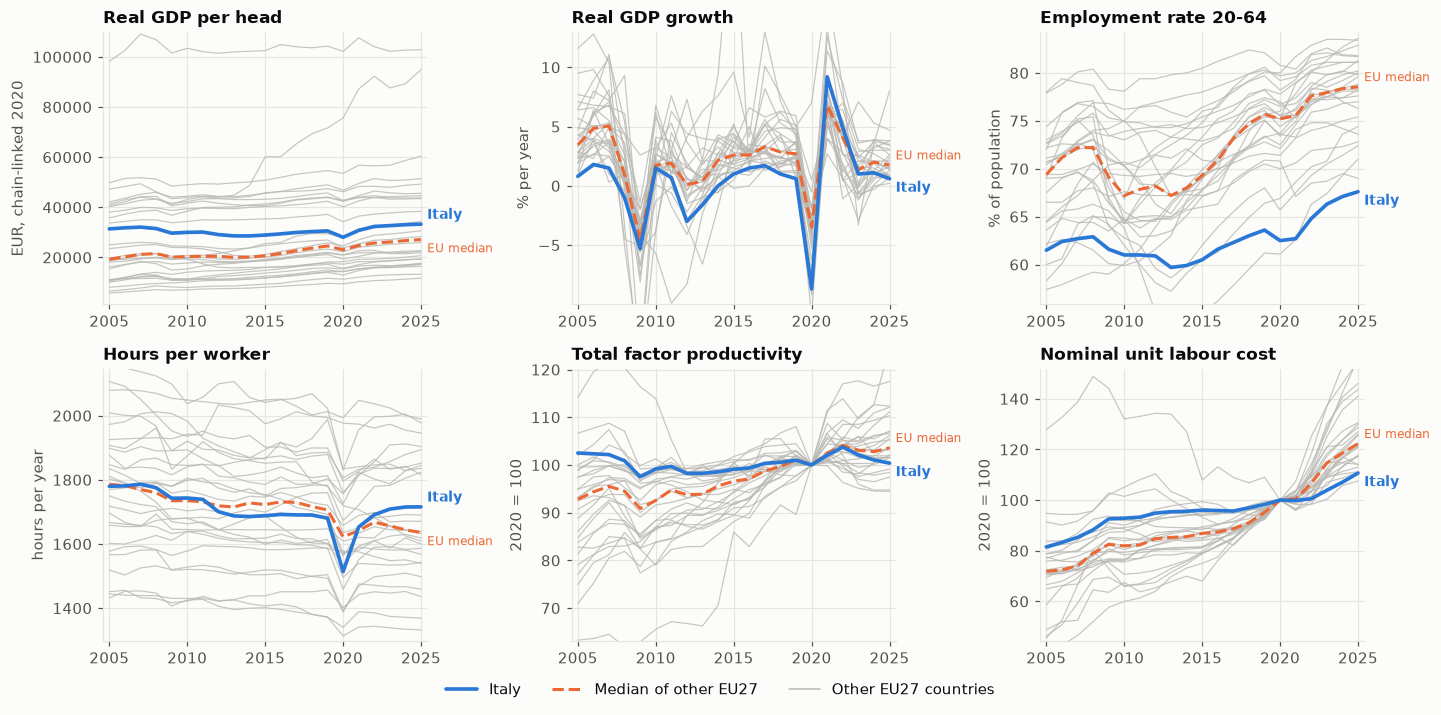

In [2]:
LAST = 2024  # last year with broad coverage (2025 is provisional for many series)
small_multiples(panel, [
    ("gdp_real_pc", "Real GDP per head", "EUR, chain-linked 2020"),
    ("gdp_growth", "Real GDP growth", "% per year"),
    ("employment_rate_20_64", "Employment rate 20-64", "% of population"),
    ("ameco_hours_per_worker", "Hours per worker", "hours per year"),
    ("ameco_tfp_index", "Total factor productivity", "2020 = 100"),
    ("nominal_ulc", "Nominal unit labour cost", "2020 = 100"),
], ncols=3, name="02_growth_overview")

iso3    ITA    DEU    FRA   ESP
year                           
2005  116.6  129.3  126.6  96.2
2010  107.6  129.8  122.8  92.2
2015   99.1  136.8  119.4  84.3
2019   95.0  136.3  113.7  83.9
2024   93.5  130.9  106.4  81.5


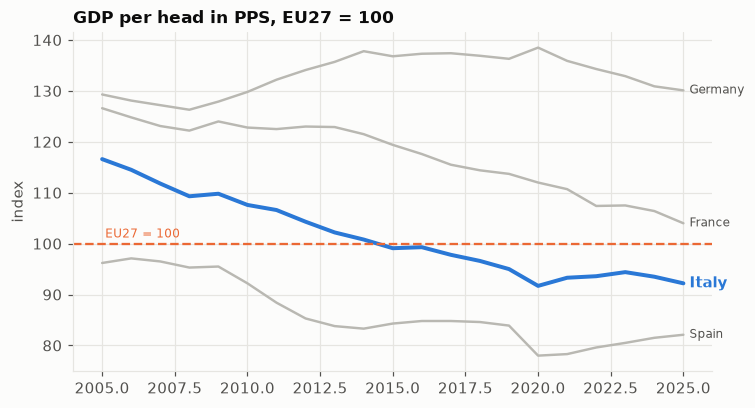

In [3]:
# GDP per head relative to Germany, France, Spain and the EU27 average (EU27 = 100, PPS)
rel = wide(panel, "gdp_pps_pc_eu27")
fig, ax = plt.subplots(figsize=(7.5, 4))
for c, lab in [("DEU", "Germany"), ("FRA", "France"), ("ESP", "Spain")]:
    ax.plot(rel.index, rel[c], color=PEER_C, lw=1.6); ax.annotate(lab, (rel.index[-1], rel[c].iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=8, color=INK2, va="center")
ax.plot(rel.index, rel[ITALY], color=ITALY_C, lw=2.6); ax.annotate("Italy", (rel.index[-1], rel[ITALY].iloc[-1]), xytext=(4, 0), textcoords="offset points", color=ITALY_C, fontweight="bold", va="center")
ax.axhline(100, color=EU_C, lw=1.5, ls="--"); ax.annotate("EU27 = 100", (rel.index[0], 100), xytext=(2, 4), textcoords="offset points", color=EU_C, fontsize=8)
ax.set_title("GDP per head in PPS, EU27 = 100"); ax.set_ylabel("index"); save(fig, "02_convergence")
print(rel.loc[[2005, 2010, 2015, 2019, 2024], [ITALY, "DEU", "FRA", "ESP"]].round(1))

*Caveat:* the EU27 average itself rises as central/eastern members catch up, so part of Italy's fall in this index is their gain, not Italy's loss. Compare with Germany/France/Spain, which are the more telling references.

,employment rate,hours per worker,productivity & demography (residual),real GDP per head
iso3,,,,
ITA,8.7,-3.7,0.2,5.2
DEU,15.6,-7.1,11.4,19.9
FRA,7.8,-0.6,5.4,12.5
ESP,5.6,-4.4,9.5,10.7
PRT,8.4,0.7,7.7,16.8
GRC,7.3,-7.7,-2.6,-3.0
EU median (excl. IT),9.6,-4.5,18.4,27.4


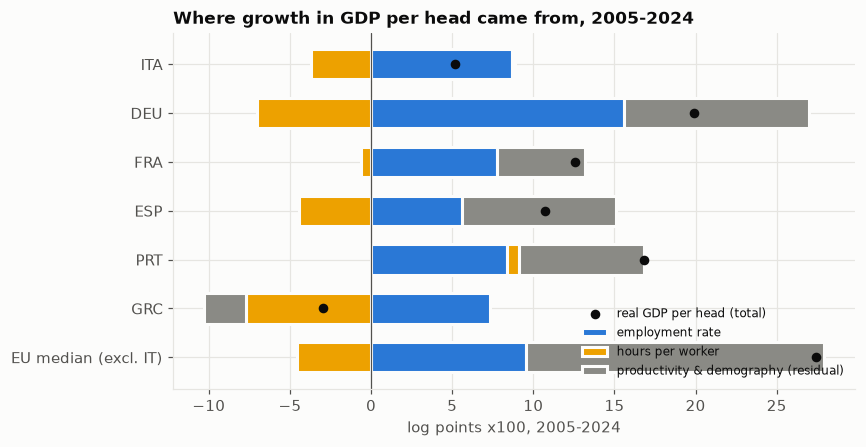

In [4]:
# Where does the GDP-per-head gap come from? Log change 2005-2024 split into employment rate, hours, and a productivity residual
dec = gdp_pc_growth_decomposition(panel, 2005, 2024)
parts = ["employment rate", "hours per worker", "productivity & demography (residual)"]
show = dec.loc[["ITA", "DEU", "FRA", "ESP", "PRT", "GRC"]].copy()
show.loc["EU median (excl. IT)"] = dec.drop("ITA").median()
fig, ax = plt.subplots(figsize=(8, 4.2))
cols = ["#2a78d6", "#eda100", "#8a8a85"]
left_pos = np.zeros(len(show)); left_neg = np.zeros(len(show))
for part, col in zip(parts, cols):
    v = show[part].values; base = np.where(v >= 0, left_pos, left_neg)
    ax.barh(range(len(show)), v, left=base, color=col, height=0.62, label=part, edgecolor=SURFACE, linewidth=2)
    left_pos += np.where(v >= 0, v, 0); left_neg += np.where(v < 0, v, 0)
ax.scatter(show["real GDP per head"], range(len(show)), color=INK, zorder=5, s=28, label="real GDP per head (total)")
ax.set_yticks(range(len(show)), show.index); ax.invert_yaxis(); ax.axvline(0, color=INK2, lw=0.8)
ax.set_xlabel("log points x100, 2005-2024"); ax.set_title("Where growth in GDP per head came from, 2005-2024")
ax.legend(loc="lower right", fontsize=8); save(fig, "02_growth_decomposition")
display(show.round(1))

In [5]:
# Italy's rank among EU27 members, selected years (1 = highest; index series such as TFP and ULC are 2020=100, so ranks are not meaningful)
rows = {}
for ind in ["gdp_real_pc", "gdp_growth", "employment_rate_20_64", "employment_rate_20_64_female", "ameco_hours_per_worker", "hicp_inflation"]:
    w = wide(panel, ind)
    rows[ind] = {y: "%d/%d" % italy_rank(w, y) for y in (2005, 2010, 2015, 2019, 2024) if not np.isnan(w.loc[y, ITALY])}
display(pd.DataFrame(rows).T)

,2005,2010,2015,2019,2024
gdp_real_pc,11/27,11/27,11/27,11/27,12/27
gdp_growth,26/27,18/27,25/27,27/27,19/27
employment_rate_20_64,24/27,25/27,25/27,26/27,27/27
employment_rate_20_64_female,26/27,26/27,26/27,26/27,27/27
ameco_hours_per_worker,14/27,14/27,16/27,15/27,11/27
hicp_inflation,16/27,18/27,13/27,24/27,25/27


## Takeaways (numbers from the cells above; Eurostat/AMECO, 2005-2024)
- **Italy is not poor, it is stagnant.** Real GDP per head is mid-table (11th-12th of 27 throughout) but grew only +5% (log points) over 2005-2024, against +27% for the median of the other members, +20% Germany, +17% Portugal, +12.5% France, +11% Spain. Of the 27 members with data only Greece (-3%) and Luxembourg (+4.4%, from a very high base) were lower.
- **The shortfall is in the productivity/demography residual**, not hours or employment: +0.2 for Italy vs +18.4 for the median. Employment rose +8.7 (median +9.6) and hours fell -3.7 (median -4.5). The residual mixes output per hour with age-structure effects, so it cannot say how much is each.
- **Employment is the structural gap in levels:** 20-64 employment was 67.1% in 2024 against a 78.4% median (27th of 27); female employment 57.4% vs 75.2% (also last).
- **Convergence went backwards:** GDP per head in PPS (EU27 = 100) fell from 116.6 to 93.5, while Germany stayed near 130. Part of this is eastern members catching up, but Spain and France show smaller falls than Italy relative to Germany.